# 🛒 Market Basket Analysis - 999 Transactions

**Author:** Divine C. Nnanna
**Date:** November, 2026
**Dataset:** 999 baskets x 16 items (True/False)

### Business Problem
A retail shop does not know which products customers buy together.
This leads to poor shelf arrangement and missed cross-selling opportunities.

### Goal
Use Association Rule Mining (Apriori) to discover which products are bought together, and give data-driven recommendations to increase sales.

### Tools
Python, Pandas, Matplotlib,  Mlxtend (Apriori), Seaborn

In [2]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

# Style for charts
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

## 1. Load Data

We load the dataset and check its shape and types.
The data is in **One-Hot Encoded** format:
- `True` = Customer bought the item
- `False` = Customer did not buy the item

We do NOT do train/test split here because Market Basket is **Unsupervised Learning**.
There is no target variable (y) to predict.
We use all 999 baskets to find patterns.

In [11]:
# Load data
df = pd.read_csv("../data/raw/basket_analysis.csv")

print(f"Shape: {df.shape}")
print(f"Rows = Transactions, Columns = Items")
print("\nFirst 5 rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum().sum())

Shape: (999, 16)
Rows = Transactions, Columns = Items

First 5 rows:


,Apple,Bread,Butter,Cheese,Corn,Dill,Eggs,Ice cream,Kidney Beans,Milk,Nutmeg,Onion,Sugar,Unicorn,Yogurt,chocolate
0,False,True,False,False,True,True,False,True,False,False,False,False,True,False,True,True
1,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,True,False,True,False,False,True,False,True,False,True,False,False,False,False,True,True
3,False,False,True,True,False,True,False,False,False,True,True,True,False,False,False,False
4,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False



Data Types:
Apple           bool
Bread           bool
Butter          bool
Cheese          bool
Corn            bool
Dill            bool
Eggs            bool
Ice cream       bool
Kidney Beans    bool
Milk            bool
Nutmeg          bool
Onion           bool
Sugar           bool
Unicorn         bool
Yogurt          bool
chocolate       bool
dtype: object

Missing values:
0


## 2. Data Cleaning

**Issue Found:** We need to make sure that each columns are sentence case and make them ready for training.

**Fix:** Convert all column names to Sentence case , strip spaces and merge duplicates.

**Decision on Data Type:** We keep data as `bool` (True/False).
Apriori from `mlxtend` requires boolean data. Changing to 0/1 (int) works,
but bool is the standard and avoids warnings. 1 = True, 0 = False, same meaning.

In [16]:
# Cleaning
print("Before cleaning:", list(df.columns))

# Ensure bool type
df = df.astype(bool)

# After cleaning
print("\nAfter cleaning:", list(df.columns))
print(f"New Shape: {df.shape}")
print(df.head())

Before cleaning: ['Apple', 'Bread', 'Butter', 'Cheese', 'Corn', 'Dill', 'Eggs', 'Ice cream', 'Kidney Beans', 'Milk', 'Nutmeg', 'Onion', 'Sugar', 'Unicorn', 'Yogurt', 'chocolate']

After cleaning: ['Apple', 'Bread', 'Butter', 'Cheese', 'Corn', 'Dill', 'Eggs', 'Ice cream', 'Kidney Beans', 'Milk', 'Nutmeg', 'Onion', 'Sugar', 'Unicorn', 'Yogurt', 'chocolate']
New Shape: (999, 16)
   Apple  Bread  Butter  Cheese   Corn   Dill   Eggs  Ice cream  Kidney Beans  \
0  False   True   False   False   True   True  False       True         False   
1  False  False   False   False  False  False  False      False         False   
2   True  False    True   False  False   True  False       True         False   
3  False  False    True    True  False   True  False      False         False   
4   True   True   False   False  False  False  False      False         False   

    Milk  Nutmeg  Onion  Sugar  Unicorn  Yogurt  chocolate  
0  False   False  False   True    False    True       True  
1   True   F

## 3. Exploratory Data Analysis (EDA)

We ask 2 questions:
1. Which items sells the most?
2. How many items does a customer buy per basket?

chocolate       421
Butter          420
Yogurt          420
Ice cream       410
Sugar           409
Kidney Beans    408
Corn            407
Milk            405
Cheese          404
Onion           403
Nutmeg          401
Dill            398
Unicorn         389
Bread           384
Eggs            384
Apple           383
dtype: int64

Most popular: chocolate (421 baskets)
Least popular: Apple (383 baskets)


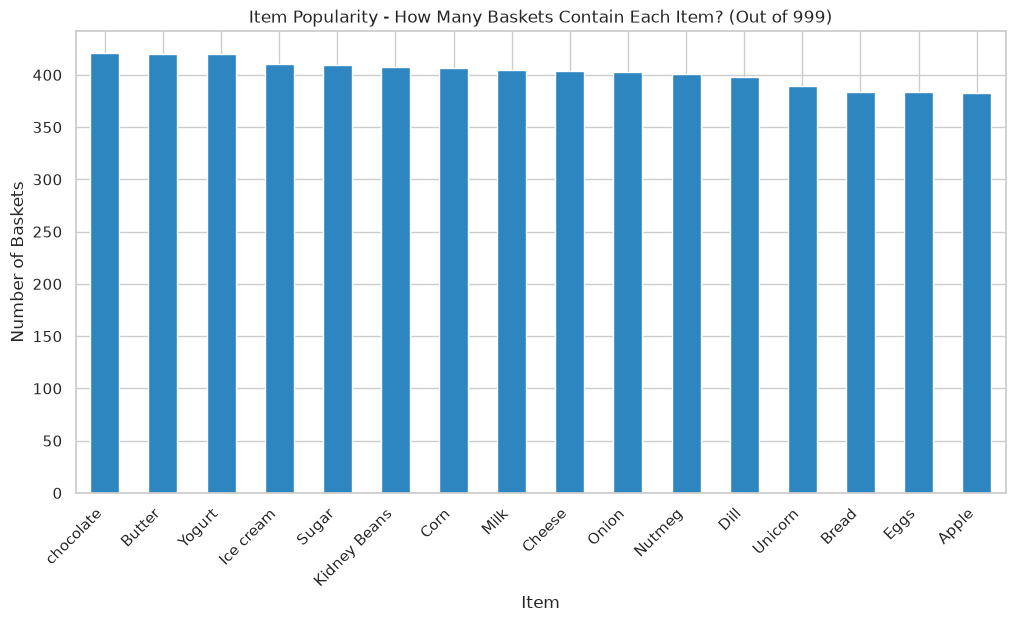

In [19]:
# 3.1 Which items sells the most?
item_counts = df.sum().sort_values(ascending=False)
print(item_counts)
print(f"\nMost popular: {item_counts.index[0]} ({item_counts.iloc[0]} baskets)")
print(f"Least popular: {item_counts.index[-1]} ({item_counts.iloc[-1]} baskets)")

# Plot
item_counts.plot(kind='bar', color='#2E86C1')
plt.title('Item Popularity - How Many Baskets Contain Each Item? (Out of 999)')
plt.ylabel('Number of Baskets')
plt.xlabel('Item')
plt.xticks(rotation=45, ha='right')
plt.show()

count    999.000000
mean       6.452452
std        2.950407
min        1.000000
25%        4.000000
50%        7.000000
75%        9.000000
max       13.000000
Name: basket_size, dtype: float64

Basket size distribution:
basket_size
1      59
2      63
3      72
4      81
5      99
6      99
7     132
8     115
9     115
10     82
11     55
12     23
13      4
Name: count, dtype: int64


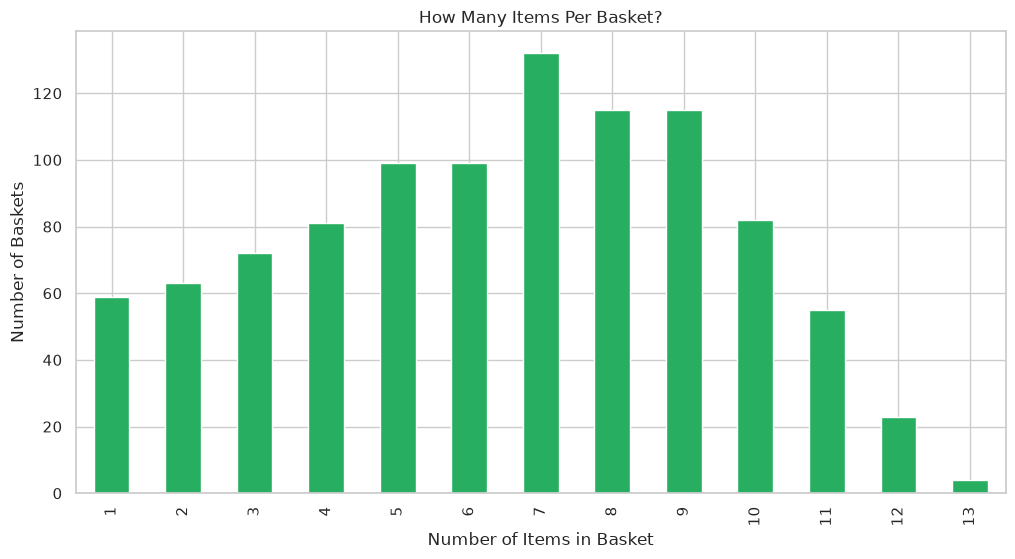

In [20]:
# 3.2 Basket Size
df['basket_size'] = df.sum(axis=1)
print(df['basket_size'].describe())
print("\nBasket size distribution:")
print(df['basket_size'].value_counts().sort_index())

# Plot
df['basket_size'].value_counts().sort_index().plot(kind='bar', color='#27AE60')
plt.title('How Many Items Per Basket?')
plt.xlabel('Number of Items in Basket')
plt.ylabel('Number of Baskets')
plt.show()

# Remove helper column before Apriori
df = df.drop(columns=['basket_size'])

## 4. Apriori - Find Frequent Itemsets

We cuse `min_support = 0.05`
This means a combination must appear in at least 5% of baskets to be considered.
5% of 999 = ~50 baskets.

We do this to avoid random one-time combinations.

In [26]:
# Find Frequent Itemsets
frequent_items = apriori(df, min_support=0.05, use_colnames=True, verbose=1)
frequent_items['length'] = frequent_items['itemsets'].apply(lambda x: len(x))

print(f"Total frequent combinations found: {len(frequent_items)}")
print(frequent_items.sort_values('support', ascending=False).head(20))

# How many 1-item, 2-item combos?
print("\nBy length:")
print(frequent_items['length'].value_counts())

Processing 135 combinations | Sampling itemset size 54
Total frequent combinations found: 947
      support                           itemsets  length
15   0.421421             frozenset({chocolate})       1
2    0.420420                frozenset({Butter})       1
14   0.420420                frozenset({Yogurt})       1
7    0.410410             frozenset({Ice cream})       1
12   0.409409                 frozenset({Sugar})       1
8    0.408408          frozenset({Kidney Beans})       1
4    0.407407                  frozenset({Corn})       1
9    0.405405                  frozenset({Milk})       1
3    0.404404                frozenset({Cheese})       1
11   0.403403                 frozenset({Onion})       1
10   0.401401                frozenset({Nutmeg})       1
5    0.398398                  frozenset({Dill})       1
13   0.389389               frozenset({Unicorn})       1
1    0.384384                 frozenset({Bread})       1
6    0.384384                  frozenset({Eggs})   

## 5. Association Rules - The Main Result

We generate rules with:
- `metric = confidence`
- `min_threshold = 0.5` -> If you buy A at least 50% chance you buy B

**How to read a rule:**
- **Antecedent:** What customer bought first (e.g. Cheese)
- **Consequent:** What customer will buy next (e.g. Kidney Beans)
- **Support:** How common is this combo in all 999 baskets?
- **Confidence:** If you buy A, what % buy B?
- **Lift:** How much more likely is B if you buy A vs random?

      - Lift = 1 -> No relationship
      - Lift > 1 -> Strong positive relationship
      - Lift < 1 -> Negative relationship 

In [33]:
# Generate rules
rules = association_rules(frequent_items, metric='confidence', min_threshold=0.5)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

# Keep only useful columns
rules_clean = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
print(f"Total rules: {len(rules_clean)}")
display(rules_clean.head(20))

# Save for API + App
rules.to_csv('../artifacts/rules.csv', index=False)
print("\nSaved to rules.csv for API and App")

Total rules: 1494


,antecedents,consequents,support,confidence,lift
0,"frozenset({Sugar, Cheese, Unicorn})",frozenset({Kidney Beans}),0.054054,0.666667,1.632353
1,"frozenset({Dill, Unicorn, Milk})",frozenset({chocolate}),0.062062,0.681319,1.616716
2,"frozenset({Corn, Sugar, Dill})",frozenset({Apple}),0.052052,0.619048,1.614696
3,"frozenset({Corn, Sugar, Unicorn})",frozenset({Apple}),0.055055,0.617978,1.611905
4,"frozenset({chocolate, Unicorn, Milk})",frozenset({Dill}),0.062062,0.639175,1.604362
5,"frozenset({Yogurt, Cheese, Ice cream})",frozenset({Kidney Beans}),0.057057,0.655172,1.604209
6,"frozenset({Onion, Dill, Kidney Beans})",frozenset({Cheese}),0.055055,0.647059,1.600029
7,"frozenset({Corn, Onion, Apple})",frozenset({Sugar}),0.054054,0.650602,1.589124
8,"frozenset({Corn, Dill, Cheese})",frozenset({Onion}),0.057057,0.640449,1.587615
9,"frozenset({Corn, Nutmeg, Milk})",frozenset({Kidney Beans}),0.055055,0.647059,1.584343



Saved to rules.csv for API and App


## 6. Strong Rules Only

We filter to only strong actionable rules
- `Lift = 1.2`
- `Confidence > 0.6`

These are the rules we will give to the business.

In [28]:
strong_rules = rules[(rules['lift'] > 1.2) & (rules['confidence'] > 0.6)]
strong_rules = strong_rules.sort_values('lift', ascending=False)
print(f"Strong rules: {len(strong_rules)}")
display(strong_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

Strong rules: 70


,antecedents,consequents,support,confidence,lift
0,"frozenset({Sugar, Cheese, Unicorn})",frozenset({Kidney Beans}),0.054054,0.666667,1.632353
1,"frozenset({Dill, Unicorn, Milk})",frozenset({chocolate}),0.062062,0.681319,1.616716
2,"frozenset({Corn, Sugar, Dill})",frozenset({Apple}),0.052052,0.619048,1.614696
3,"frozenset({Corn, Sugar, Unicorn})",frozenset({Apple}),0.055055,0.617978,1.611905
4,"frozenset({chocolate, Unicorn, Milk})",frozenset({Dill}),0.062062,0.639175,1.604362
...,...,...,...,...,...
161,"frozenset({Onion, Unicorn, Ice cream})",frozenset({chocolate}),0.053053,0.602273,1.429146
172,"frozenset({Dill, Unicorn})",frozenset({chocolate}),0.101101,0.601190,1.426578
181,"frozenset({Corn, Onion, Unicorn})",frozenset({chocolate}),0.054054,0.600000,1.423753
182,"frozenset({Dill, Kidney Beans, Milk})",frozenset({chocolate}),0.054054,0.600000,1.423753


## 7. Visualization

Top 10 rules by Lift - Which combinations are strongest?

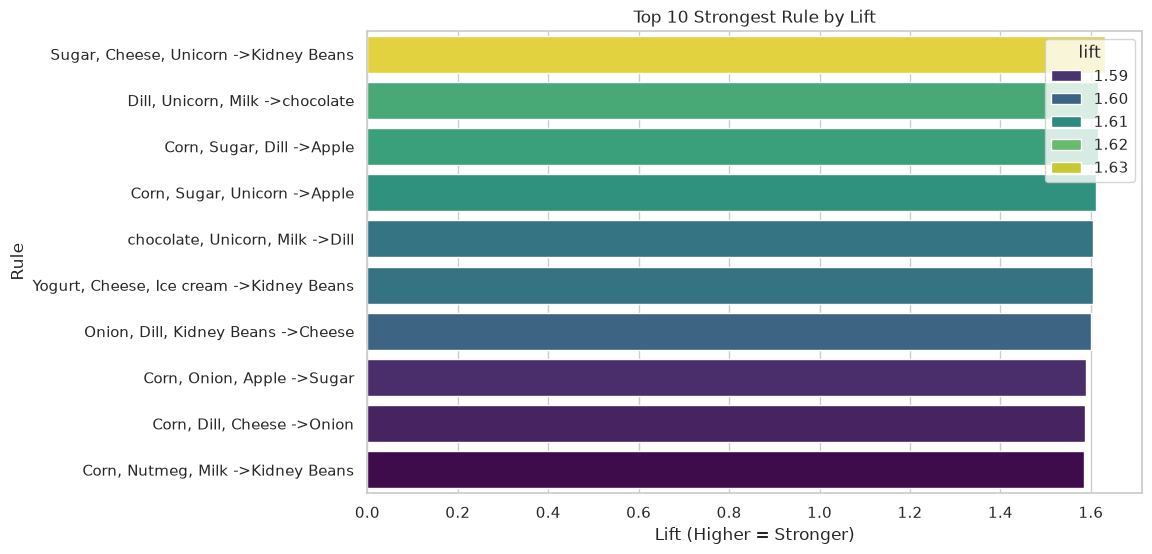

In [31]:
top10 = strong_rules.head(10).copy()
top10['rule'] = top10['antecedents'].apply(lambda x: ', '.join(list(x))) + " ->" + top10['consequents'].apply(lambda x: ', '.join(list(x)))

plt.figure(figsize=(10, 6))
sns.barplot(data=top10, y='rule', x='lift', palette='viridis', hue='lift')
plt.title('Top 10 Strongest Rule by Lift')
plt.xlabel('Lift (Higher = Stronger)')
plt.ylabel('Rule')
plt.show()

## 8. Business Recommendations & Conclusion

### Key Findings (Fill with your real numbers after running)
1. **Kidney Beans is the King Add-on:** It appears as consequent in Cheese -> Kidney Beans, Yogurt -> Kidney Beans, Corn -> Kidney Beans. Customers do not for Kidney Beans alone, they add it.
2. **Dill is the Connector:** Dill connects to Chocolate, Apple, Onion. Promoting Dill will lift multiple products.
3. **Onion is a Trigger:** Onion -> Cheese and Onion -> Sugar. Onion buyers are high-value baskets.

### Recommendations
1. **Shelf Placement:** Put Cheese next to Kidney Beans, and Onion next to Cheese. Reduce customer walking distance.
2. **Bundle Offer:** Create a bundle "Buy Cheese, Get Kidney Beans 10% Off".
3. **Promotion:** When Dill is on promo, also put Chocolate and Apple near it.
4. **Cross-Selling in App:** If user adds Cheese to cart, automatically recommend Kidney Beans.

### Limitations
- Data is only 999 baskets, one shop, one period.
- We do not know price, so we cannot calculate profit, only frequency.
- Correlation is not causation - a rule does not mean A causes B, only that they appear together.

### Next Steps
- Build FastAPI to serve these rules
- Build Streamlit App for shop staff to use
- Test bundle in real shop for 2 weeks and measure lift in sales